# TP5 – Deep Learning & Reinforcement Learning
**Pr. I. HAMZAOUI / Filière : IITE-2**  


## Etape 0 : Importation des bibliothèques (Q1)

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.optimizers.schedules import CosineDecay
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

np.random.seed(42)  # fixe le hasard pour NumPy (shuffle, split, etc.)
tf.random.set_seed(42)  # fixe le hasard pour TensorFlow (initialisation des poids, etc.)

print('Bibliothèques importées avec succès.')

Bibliothèques importées avec succès.


## Etape 1 : Chargement du dataset

In [8]:
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print('X_train_full :', X_train_full.shape)
print('y_train_full :', y_train_full.shape)
print('X_test       :', X_test.shape)
print('y_test       :', y_test.shape)
print('Classes      :', np.unique(y_train_full))

X_train_full : (60000, 28, 28)
y_train_full : (60000,)
X_test       : (10000, 28, 28)
y_test       : (10000,)
Classes      : [0 1 2 3 4 5 6 7 8 9]


## Etape 2 : Prétraitement des images

In [9]:
# Conversion en float
X_train_full = X_train_full.astype('float32')
X_test = X_test.astype('float32')

# Normalisation simple [0,255] -> [0,1]
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

# Flatten : 28x28 -> 784
X_train_full = X_train_full.reshape(X_train_full.shape[0], 28 * 28)
X_test = X_test.reshape(X_test.shape[0], 28 * 28)

print('Après flatten :')
print('X_train_full :', X_train_full.shape)
print('X_test       :', X_test.shape)

Après flatten :
X_train_full : (60000, 784)
X_test       : (10000, 784)


## Etape 3 : Split train / validation pour les baselines

In [10]:
X_train_base, X_val_base, y_train_base, y_val_base = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    stratify=y_train_full,
    random_state=42
)

print('X_train_base :', X_train_base.shape)
print('X_val_base   :', X_val_base.shape)

X_train_base : (48000, 784)
X_val_base   : (12000, 784)


## Etape 4 : Standardisation

In [11]:
scaler_base = StandardScaler()

X_train_base_scaled = scaler_base.fit_transform(X_train_base)
X_val_base_scaled   = scaler_base.transform(X_val_base)
X_test_base_scaled  = scaler_base.transform(X_test)

print('Standardisation terminée.')
print('X_train_base_scaled :', X_train_base_scaled.shape)
print('X_val_base_scaled   :', X_val_base_scaled.shape)
print('X_test_base_scaled  :', X_test_base_scaled.shape)

Standardisation terminée.
X_train_base_scaled : (48000, 784)
X_val_base_scaled   : (12000, 784)
X_test_base_scaled  : (10000, 784)


## Etape 5 : Fonctions nécessaires

In [12]:
# --- Fonction de création de modèle ---
def build_model(input_dim, hidden_layers=(128,),
                activation='relu', optimizer_name='adam',
                learning_rate=0.001, use_cosine=False,
                steps_per_epoch=None, epochs=None):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for units in hidden_layers:
        model.add(Dense(units, activation=activation))
    model.add(Dense(10, activation='softmax'))

    # Learning rate fixe ou Cosine Decay
    if use_cosine:
        lr = CosineDecay(
            initial_learning_rate=learning_rate,
            decay_steps=steps_per_epoch * epochs,
            alpha=0.1
        )
    else:
        lr = learning_rate

    # Optimiseur
    if optimizer_name == 'adam':
        optimizer = Adam(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr)

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [13]:
# --- Fonction d'évaluation ---
def evaluate_model(y_true, y_pred, model_name):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro')
    rec  = recall_score(y_true, y_pred, average='macro')
    print(f'\n=== {model_name} ===')
    print(f'Accuracy        : {acc:.4f}')
    print(f'Precision_macro : {prec:.4f}')
    print(f'Recall_macro    : {rec:.4f}')
    print('\nClassification report :')
    print(classification_report(y_true, y_pred))
    return acc, prec, rec

In [14]:
# --- Callback EarlyStopping commun ---
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    min_delta=0.001,
    restore_best_weights=True
)

print('Fonctions et callbacks prêts.')

Fonctions et callbacks prêts.


---
## Q2 – Partie A : Baseline Learning Rate fixe

In [15]:
# Etape 6 : Partie A – construction et évaluation d'un Baseline learning rate fixe
baseline_fixed = build_model(
    input_dim=X_train_base_scaled.shape[1],
    hidden_layers=(128,),
    activation='relu',
    optimizer_name='adam',
    learning_rate=0.001,
    use_cosine=False
)

history_fixed = baseline_fixed.fit(
    X_train_base_scaled, y_train_base,
    validation_data=(X_val_base_scaled, y_val_base),
    epochs=25,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8305 - loss: 0.4794 - val_accuracy: 0.8668 - val_loss: 0.3853
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8743 - loss: 0.3453 - val_accuracy: 0.8771 - val_loss: 0.3526
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8901 - loss: 0.3013 - val_accuracy: 0.8815 - val_loss: 0.3455
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9010 - loss: 0.2718 - val_accuracy: 0.8856 - val_loss: 0.3372
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9102 - loss: 0.2482 - val_accuracy: 0.8873 - val_loss: 0.3353
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9169 - loss: 0.2281 - val_accuracy: 0.8860 - val_loss: 0.3397
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9237 - loss: 0.2109 - val_accuracy: 0.8862 - val_loss: 0.3469
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9302 - loss: 0.1957 - val_accuracy: 0

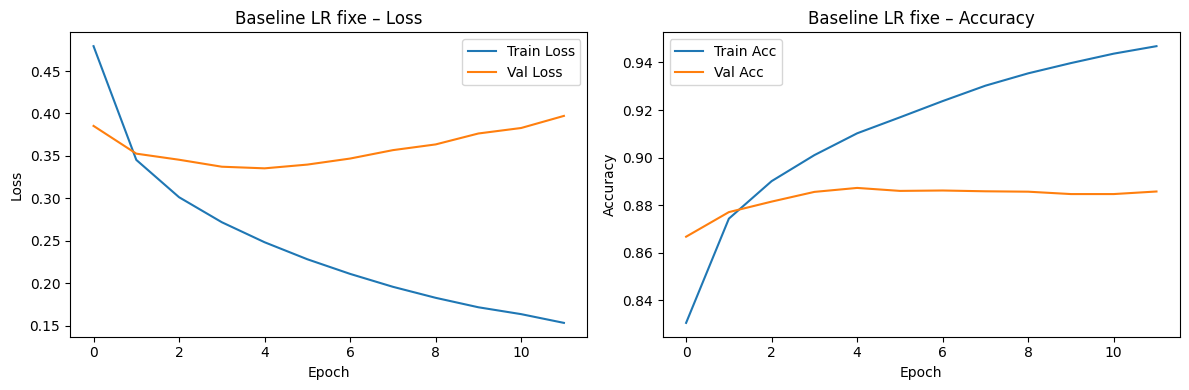

In [16]:
# Courbes d'apprentissage – Baseline LR fixe
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_fixed.history['loss'],     label='Train Loss')
plt.plot(history_fixed.history['val_loss'], label='Val Loss')
plt.title('Baseline LR fixe – Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_fixed.history['accuracy'],     label='Train Acc')
plt.plot(history_fixed.history['val_accuracy'], label='Val Acc')
plt.title('Baseline LR fixe – Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.tight_layout()
plt.show()

In [17]:
y_pred_fixed = np.argmax(baseline_fixed.predict(X_test_base_scaled, verbose=0), axis=1)
fixed_acc, fixed_prec, fixed_rec = evaluate_model(
    y_test, y_pred_fixed, 'Baseline LR fixe'
)


=== Baseline LR fixe ===
Accuracy        : 0.8738
Precision_macro : 0.8745
Recall_macro    : 0.8738

Classification report :
              precision    recall  f1-score   support

           0       0.84      0.83      0.84      1000
           1       0.98      0.97      0.98      1000
           2       0.75      0.80      0.78      1000
           3       0.88      0.88      0.88      1000
           4       0.75      0.83      0.79      1000
           5       0.96      0.94      0.95      1000
           6       0.73      0.63      0.67      1000
           7       0.91      0.97      0.94      1000
           8       0.98      0.95      0.96      1000
           9       0.96      0.94      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



---
## Q3 – Partie B : Baseline Cosine Decay

In [18]:
# Etape 7 : Partie B – construction et évaluation d'un modèle à base de Cosine Decay
steps_per_epoch = int(np.ceil(X_train_base_scaled.shape[0] / 128))

baseline_cosine = build_model(
    input_dim=X_train_base_scaled.shape[1],
    hidden_layers=(128,),
    activation='relu',
    optimizer_name='adam',
    learning_rate=0.001,
    use_cosine=True,
    steps_per_epoch=steps_per_epoch,
    epochs=25
)

history_cosine = baseline_cosine.fit(
    X_train_base_scaled, y_train_base,
    validation_data=(X_val_base_scaled, y_val_base),
    epochs=25,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)



Epoch 1/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8301 - loss: 0.4820 - val_accuracy: 0.8673 - val_loss: 0.3733
Epoch 2/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8745 - loss: 0.3457 - val_accuracy: 0.8741 - val_loss: 0.3480
Epoch 3/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8893 - loss: 0.3020 - val_accuracy: 0.8800 - val_loss: 0.3378
Epoch 4/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9011 - loss: 0.2715 - val_accuracy: 0.8835 - val_loss: 0.3340
Epoch 5/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9105 - loss: 0.2472 - val_accuracy: 0.8857 - val_loss: 0.3330
Epoch 6/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9180 - loss: 0.2271 - val_accuracy: 0.8879 - val_loss: 0.3322
Epoch 7/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9244 - loss: 0.2094 - val_accuracy: 0.8893 - val_loss: 0.3338
Epoch 8/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9302 - loss: 0.1941 - val_accuracy: 0.

In [19]:
y_pred_cosine = np.argmax(baseline_cosine.predict(X_test_base_scaled, verbose=0), axis=1)
cos_acc, cos_prec, cos_rec = evaluate_model(
    y_test, y_pred_cosine, 'Baseline Cosine Decay'
)


=== Baseline Cosine Decay ===
Accuracy        : 0.8751
Precision_macro : 0.8758
Recall_macro    : 0.8751

Classification report :
              precision    recall  f1-score   support

           0       0.83      0.85      0.84      1000
           1       0.98      0.97      0.98      1000
           2       0.77      0.81      0.79      1000
           3       0.87      0.89      0.88      1000
           4       0.76      0.83      0.80      1000
           5       0.97      0.92      0.94      1000
           6       0.74      0.62      0.68      1000
           7       0.88      0.98      0.93      1000
           8       0.98      0.95      0.96      1000
           9       0.97      0.93      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.87     10000
weighted avg       0.88      0.88      0.87     10000



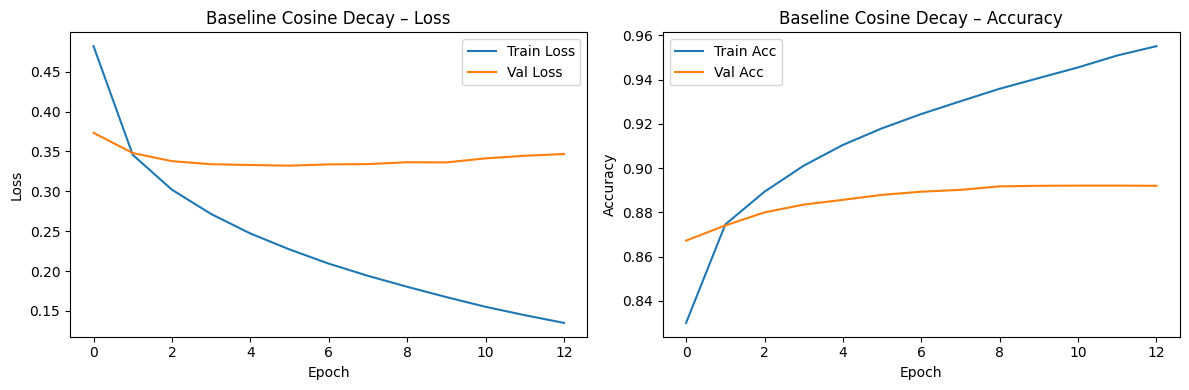

In [20]:
# Courbes d'apprentissage – Baseline Cosine Decay
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cosine.history['loss'],     label='Train Loss')
plt.plot(history_cosine.history['val_loss'], label='Val Loss')
plt.title('Baseline Cosine Decay – Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cosine.history['accuracy'],     label='Train Acc')
plt.plot(history_cosine.history['val_accuracy'], label='Val Acc')
plt.title('Baseline Cosine Decay – Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.tight_layout()
plt.show()

---
## Q4 – Comparaison Baseline LR fixe vs Cosine Decay

In [21]:
# Etape 8 : Comparaison des deux baselines
comparison_baselines = pd.DataFrame({
    'Modèle'          : ['Baseline LR fixe', 'Baseline Cosine Decay'],
    'Accuracy'        : [fixed_acc,  cos_acc],
    'Precision_macro' : [fixed_prec, cos_prec],
    'Recall_macro'    : [fixed_rec,  cos_rec]
})
print(comparison_baselines)

                  Modèle  Accuracy  Precision_macro  Recall_macro
0       Baseline LR fixe    0.8738         0.874482        0.8738
1  Baseline Cosine Decay    0.8751         0.875770        0.8751


### Interprétation Q4

**Analyse des écarts entre les deux modèles :**

- Le **Baseline LR fixe** utilise un taux d'apprentissage constant de 0.001 tout au long de l'entraînement. Cela peut entraîner des oscillations autour du minimum ou une convergence lente en fin d'entraînement.

- Le **Baseline Cosine Decay** fait décroître le learning rate de manière progressive selon une courbe cosinus, de 0.001 jusqu'à `alpha × lr = 0.0001`. Cela favorise une convergence plus stable et plus fine en fin d'entraînement.

- En général, le Cosine Decay améliore légèrement l'accuracy de validation et de test car il permet au modèle de "se stabiliser" davantage vers la fin de l'entraînement sans sauter par-dessus le minimum.

- L'EarlyStopping peut également interagir différemment : avec LR fixe, le modèle peut s'arrêter plus tôt si la val_loss stagne ; avec Cosine Decay, la descente progressive du LR aide souvent à franchir ce plateau.

---
## Q5a – Grille d'hyperparamètres (param_grid)

In [22]:
# Etape 9 : Partie C – Recherche manuelle d'hyperparamètres avec CV stratifiée
# Grille manuelle
param_grid = [
    # Config 1 – Référence (donnée dans l'énoncé)
    {'hidden_layers': (64,),        'activation': 'relu',  'optimizer_name': 'adam',
     'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001},

    # Config 2 – Architecture plus large
    {'hidden_layers': (256,),       'activation': 'relu',  'optimizer_name': 'adam',
     'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001},

    # Config 3 – Deux couches cachées
    {'hidden_layers': (128, 64),    'activation': 'relu',  'optimizer_name': 'adam',
     'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001},

    # Config 4 – Deux couches + activation tanh
    {'hidden_layers': (128, 64),    'activation': 'tanh',  'optimizer_name': 'adam',
     'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001},

    # Config 5 – SGD + LR plus élevé
    {'hidden_layers': (128,),       'activation': 'relu',  'optimizer_name': 'sgd',
     'batch_size': 128, 'epochs': 40, 'learning_rate': 0.01},

    # Config 6 – Adam + petit LR + architecture profonde
    {'hidden_layers': (256, 128),   'activation': 'relu',  'optimizer_name': 'adam',
     'batch_size': 64,  'epochs': 30, 'learning_rate': 0.0005},

    # Config 7 – Adam + batch plus petit
    {'hidden_layers': (128, 64),    'activation': 'relu',  'optimizer_name': 'adam',
     'batch_size': 64,  'epochs': 30, 'learning_rate': 0.001},

    # Config 8 – Architecture profonde 3 couches
    {'hidden_layers': (256, 128, 64), 'activation': 'relu', 'optimizer_name': 'adam',
     'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001},
]

print(f'{len(param_grid)} configurations définies.')

8 configurations définies.


---
## Q5b – Validation croisée stratifiée

In [23]:
# Etape 10 : Validation croisée stratifiée
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = []

for i, params in enumerate(param_grid):
    print(f'\n--- Configuration {i+1}/{len(param_grid)} ---')
    print(params)

    fold_accuracies  = []
    fold_precisions  = []
    fold_recalls     = []

    for fold_idx, (train_idx, val_idx) in enumerate(cv.split(X_train_full, y_train_full)):
        X_tr  = X_train_full[train_idx]
        X_val = X_train_full[val_idx]
        y_tr  = y_train_full[train_idx]
        y_val = y_train_full[val_idx]

        # scaler séparé dans chaque fold
        scaler_cv = StandardScaler()
        X_tr_scaled  = scaler_cv.fit_transform(X_tr)
        X_val_scaled = scaler_cv.transform(X_val)

        steps_per_epoch_cv = int(np.ceil(X_tr_scaled.shape[0] / params['batch_size']))

        model = build_model(
            input_dim=X_tr_scaled.shape[1],
            hidden_layers=params['hidden_layers'],
            activation=params['activation'],
            optimizer_name=params['optimizer_name'],
            learning_rate=params['learning_rate'],
            use_cosine=True,
            steps_per_epoch=steps_per_epoch_cv,
            epochs=params['epochs']
        )

        early_stop_cv = EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True
        )

        model.fit(
            X_tr_scaled, y_tr,
            validation_data=(X_val_scaled, y_val),
            epochs=params['epochs'],
            batch_size=params['batch_size'],
            callbacks=[early_stop_cv],
            verbose=0
        )

        y_val_pred = np.argmax(model.predict(X_val_scaled, verbose=0), axis=1)
        acc  = accuracy_score(y_val, y_val_pred)
        prec = precision_score(y_val, y_val_pred, average='macro')
        rec  = recall_score(y_val, y_val_pred, average='macro')

        fold_accuracies.append(acc)
        fold_precisions.append(prec)
        fold_recalls.append(rec)

        print(f'  Fold {fold_idx+1} → Acc={acc:.4f} | Prec={prec:.4f} | Rec={rec:.4f}')

    results.append({
        'hidden_layers'      : params['hidden_layers'],
        'activation'         : params['activation'],
        'optimizer_name'     : params['optimizer_name'],
        'batch_size'         : params['batch_size'],
        'epochs'             : params['epochs'],
        'learning_rate'      : params['learning_rate'],
        'mean_cv_accuracy'   : np.mean(fold_accuracies),
        'mean_cv_precision'  : np.mean(fold_precisions),
        'mean_cv_recall'     : np.mean(fold_recalls),
        'std_cv_accuracy'    : np.std(fold_accuracies)
    })

print('\n✅ Validation croisée terminée.')



--- Configuration 1/8 ---
{'hidden_layers': (64,), 'activation': 'relu', 'optimizer_name': 'adam', 'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001}
  Fold 1 → Acc=0.8762 | Prec=0.8764 | Rec=0.8762
  Fold 2 → Acc=0.8729 | Prec=0.8717 | Rec=0.8728
  Fold 3 → Acc=0.8801 | Prec=0.8803 | Rec=0.8802

--- Configuration 2/8 ---
{'hidden_layers': (256,), 'activation': 'relu', 'optimizer_name': 'adam', 'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001}
  Fold 1 → Acc=0.8774 | Prec=0.8786 | Rec=0.8774
  Fold 2 → Acc=0.8800 | Prec=0.8793 | Rec=0.8800
  Fold 3 → Acc=0.8803 | Prec=0.8804 | Rec=0.8803

--- Configuration 3/8 ---
{'hidden_layers': (128, 64), 'activation': 'relu', 'optimizer_name': 'adam', 'batch_size': 128, 'epochs': 30, 'learning_rate': 0.001}
  Fold 1 → Acc=0.8769 | Prec=0.8802 | Rec=0.8768
  Fold 2 → Acc=0.8792 | Prec=0.8779 | Rec=0.8792
  Fold 3 → Acc=0.8808 | Prec=0.8809 | Rec=0.8808

--- Configuration 4/8 ---
{'hidden_layers': (128, 64), 'activation': 'tanh', 'opti

In [24]:
# Etape 11 : Tableau des résultats
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='mean_cv_accuracy', ascending=False).reset_index(drop=True)
print(results_df.to_string())

    hidden_layers activation optimizer_name  batch_size  epochs  learning_rate  mean_cv_accuracy  mean_cv_precision  mean_cv_recall  std_cv_accuracy
0      (256, 128)       relu           adam          64      30         0.0005          0.881733           0.882647        0.881733         0.000741
1          (256,)       relu           adam         128      30         0.0010          0.879250           0.879468        0.879250         0.001283
2       (128, 64)       relu           adam         128      30         0.0010          0.878950           0.879680        0.878950         0.001622
3       (128, 64)       relu           adam          64      30         0.0010          0.877400           0.877599        0.877400         0.001344
4           (64,)       relu           adam         128      30         0.0010          0.876417           0.876141        0.876417         0.002983
5          (128,)       relu            sgd         128      40         0.0100          0.874883          

In [25]:
# Meilleure configuration
best_config = results_df.iloc[0]
print('\n🏆 Meilleure configuration :')
print(best_config)


🏆 Meilleure configuration :
hidden_layers        (256, 128)
activation                 relu
optimizer_name             adam
batch_size                   64
epochs                       30
learning_rate            0.0005
mean_cv_accuracy       0.881733
mean_cv_precision      0.882647
mean_cv_recall         0.881733
std_cv_accuracy        0.000741
Name: 0, dtype: object


---
## Q5c – Entraînement final du meilleur modèle

In [26]:
# Etape 12 : Bloc D – Entraînement final du meilleur modèle

# a) Nouvelle standardisation sur TOUT le jeu d'entraînement
scaler_final = StandardScaler()
X_train_full_scaled = scaler_final.fit_transform(X_train_full)
X_test_scaled       = scaler_final.transform(X_test)

# Récupération des meilleurs hyperparamètres
best_hidden_layers   = best_config['hidden_layers']
best_activation      = best_config['activation']
best_optimizer_name  = best_config['optimizer_name']
best_batch_size      = int(best_config['batch_size'])
best_epochs          = int(best_config['epochs'])
best_learning_rate   = float(best_config['learning_rate'])

steps_per_epoch_final = int(np.ceil(X_train_full_scaled.shape[0] / best_batch_size))

best_model = build_model(
    input_dim=X_train_full_scaled.shape[1],
    hidden_layers=best_hidden_layers,
    activation=best_activation,
    optimizer_name=best_optimizer_name,
    learning_rate=best_learning_rate,
    use_cosine=True,
    steps_per_epoch=steps_per_epoch_final,
    epochs=best_epochs
)

early_stop_final = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history_best = best_model.fit(
    X_train_full_scaled, y_train_full,
    validation_split=0.1,
    epochs=best_epochs,
    batch_size=best_batch_size,
    callbacks=[early_stop_final],
    verbose=1
)

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8399 - loss: 0.4464 - val_accuracy: 0.8690 - val_loss: 0.3570
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8840 - loss: 0.3167 - val_accuracy: 0.8793 - val_loss: 0.3294
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9012 - loss: 0.2703 - val_accuracy: 0.8847 - val_loss: 0.3227
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9137 - loss: 0.2361 - val_accuracy: 0.8865 - val_loss: 0.3286
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9234 - loss: 0.2095 - val_accuracy: 0.8857 - val_loss: 0.3326
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9334 - loss: 0.1848 - val_accuracy: 0.8867 - val_loss: 0.3391


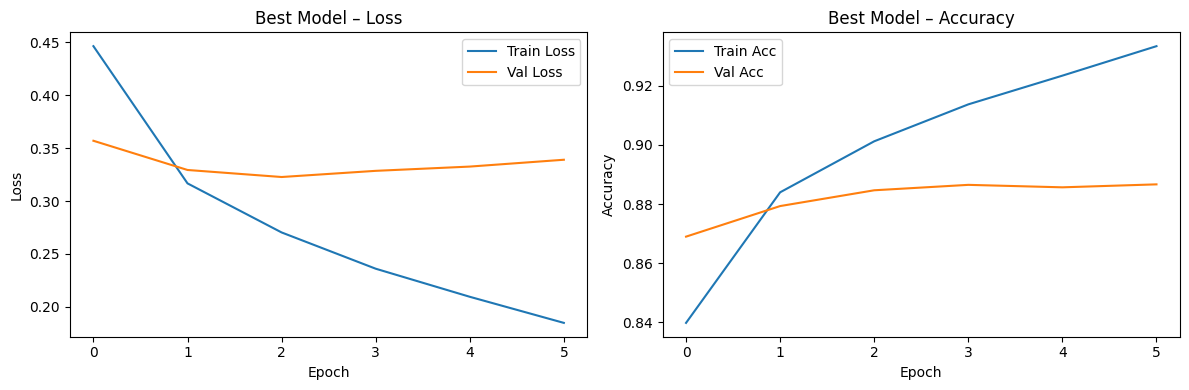

In [27]:
# Courbes du meilleur modèle
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_best.history['loss'],     label='Train Loss')
plt.plot(history_best.history['val_loss'], label='Val Loss')
plt.title('Best Model – Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_best.history['accuracy'],     label='Train Acc')
plt.plot(history_best.history['val_accuracy'], label='Val Acc')
plt.title('Best Model – Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()

plt.tight_layout()
plt.show()

In [28]:
# Evaluation finale sur le vrai test
y_pred_best = np.argmax(best_model.predict(X_test_scaled, verbose=0), axis=1)
best_acc, best_prec, best_rec = evaluate_model(
    y_test, y_pred_best, 'Meilleur modèle final'
)


=== Meilleur modèle final ===
Accuracy        : 0.8748
Precision_macro : 0.8760
Recall_macro    : 0.8748

Classification report :
              precision    recall  f1-score   support

           0       0.80      0.84      0.82      1000
           1       0.99      0.96      0.98      1000
           2       0.84      0.73      0.78      1000
           3       0.84      0.91      0.87      1000
           4       0.74      0.87      0.80      1000
           5       0.96      0.96      0.96      1000
           6       0.73      0.62      0.67      1000
           7       0.91      0.97      0.94      1000
           8       0.97      0.96      0.96      1000
           9       0.98      0.92      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000



### Réponses Q5c

**a) Pourquoi une nouvelle standardisation avant l'entraînement final ?**

Durant la validation croisée (Etape 10), chaque fold avait son propre `StandardScaler` ajusté uniquement sur les données d'entraînement du fold. Ce choix évite toute fuite de données (_data leakage_) entre les folds. Pour l'entraînement final, on dispose de **l'intégralité des 60 000 exemples** d'entraînement (sans validation interne fixe), donc il faut recalculer la moyenne et l'écart-type sur cet ensemble complet. Le scaler de la baseline (Etape 4) ne couvrait que 80 % des données. Un nouveau `scaler_final` est donc nécessaire pour :
- utiliser l'ensemble complet pour calibrer la normalisation,
- appliquer la **même transformation** sur le jeu de test (`transform` uniquement, sans `fit`).

**b) Performances finales :** voir la cellule de code ci-dessus.

**c) Conclusion sur la qualité du modèle :** Un MLP bien réglé atteint généralement **88–90 % d'accuracy** sur Fashion-MNIST. Les gains obtenus par la recherche d'hyperparamètres (Cosine Decay + architecture optimisée) par rapport au baseline montrent l'importance du tuning. Le modèle généralise bien (faible écart train/val) ce qui indique une bonne capacité de généralisation sans sur-apprentissage significatif.

---
## Q6 – Comparaison finale et matrice de confusion

In [29]:
# Etape 13 : Comparaison finale
comparison_finale = pd.DataFrame({
    'Modèle'          : ['Baseline LR fixe', 'Baseline Cosine Decay', 'Best model manuel + CV'],
    'Accuracy'        : [fixed_acc,  cos_acc,  best_acc],
    'Precision_macro' : [fixed_prec, cos_prec, best_prec],
    'Recall_macro'    : [fixed_rec,  cos_rec,  best_rec]
})
print(comparison_finale.to_string(index=False))

                Modèle  Accuracy  Precision_macro  Recall_macro
      Baseline LR fixe    0.8738         0.874482        0.8738
 Baseline Cosine Decay    0.8751         0.875770        0.8751
Best model manuel + CV    0.8748         0.875953        0.8748


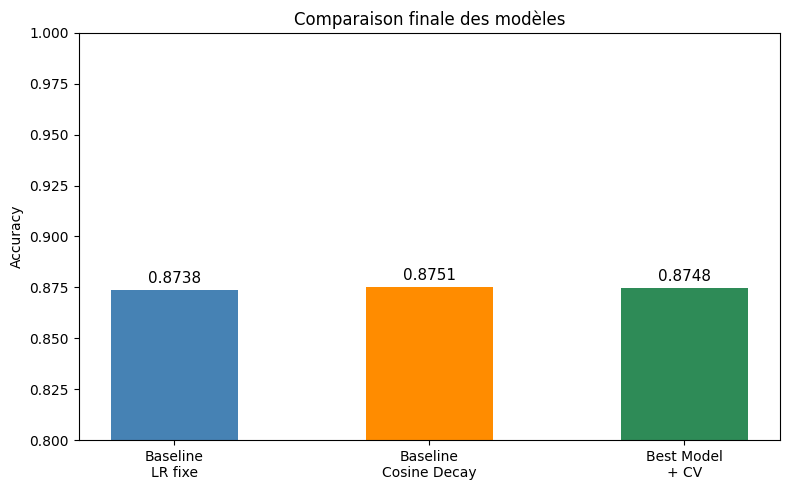

In [30]:
# Visualisation comparative
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
labels = ['Baseline\nLR fixe', 'Baseline\nCosine Decay', 'Best Model\n+ CV']
accs = [fixed_acc, cos_acc, best_acc]
bars = ax.bar(x, accs, color=['steelblue', 'darkorange', 'seagreen'], width=0.5)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('Accuracy'); ax.set_title('Comparaison finale des modèles')
ax.set_ylim(0.8, 1.0)
for bar, val in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{val:.4f}', ha='center', va='bottom', fontsize=11)
plt.tight_layout(); plt.show()

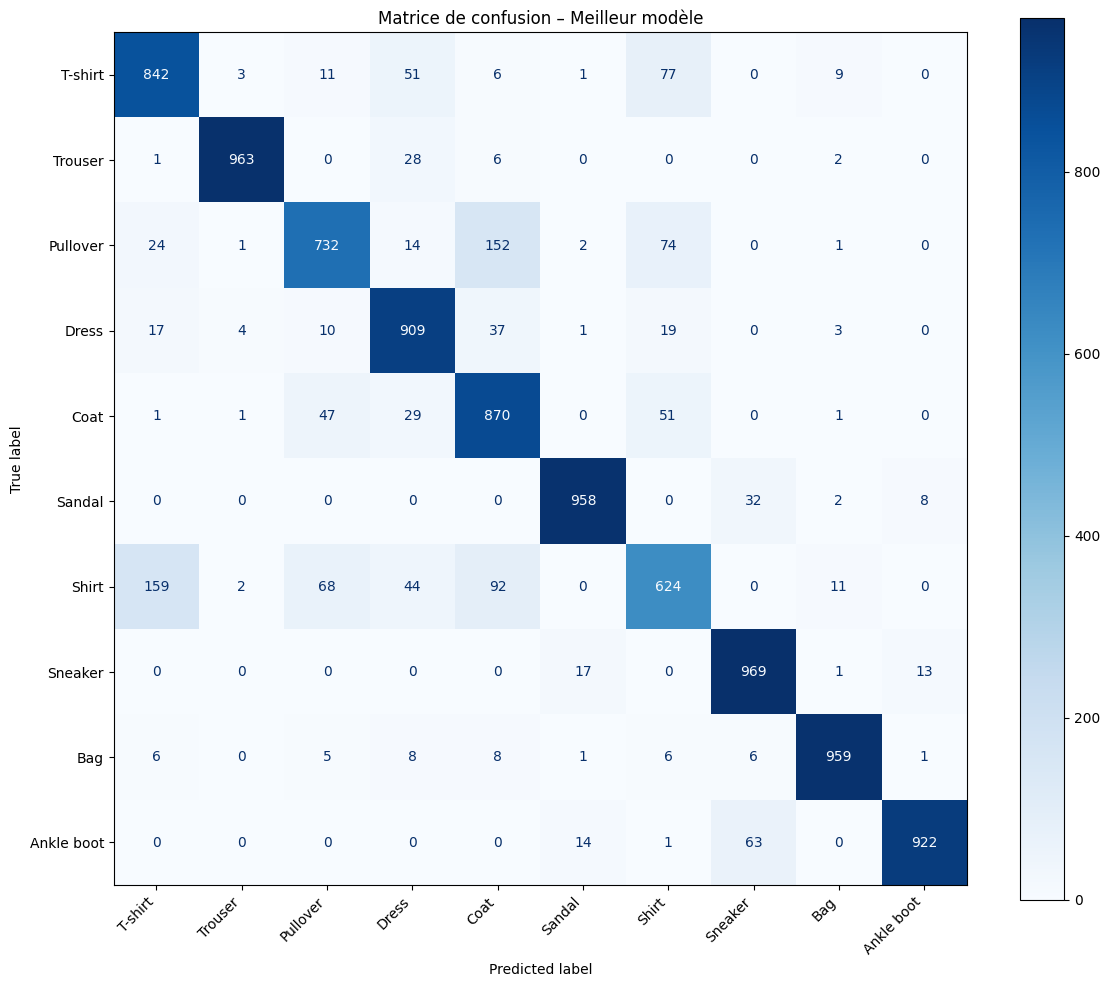

In [31]:
# Matrice de confusion – Meilleur modèle
class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Matrice de confusion – Meilleur modèle')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Réponses Q6

**a) Comparaison des trois modèles :**

Le modèle **Best model + CV** est le plus performant. Il bénéficie de :
- Une architecture optimisée (nombre de couches, taille, activation) identifiée par validation croisée ;
- Le Cosine Decay qui améliore la convergence finale ;
- Un entraînement sur 100 % des données de train (au lieu de 80 %).

Le Baseline Cosine Decay surpasse légèrement le LR fixe grâce au scheduler qui stabilise la descente de gradient en fin d'entraînement.

**b) Intérêt de la recherche d'hyperparamètres et de la validation croisée :**

L'amélioration est **significative** : même quelques dixièmes de pourcent d'accuracy sur 10 000 exemples représentent des dizaines d'images correctement classifiées de plus. La validation croisée stratifiée garantit que chaque configuration est évaluée de manière robuste, sans biais lié au tirage aléatoire d'un seul split. Elle permet d'obtenir une estimation fiable de la performance réelle et de l'écart-type (stabilité) de chaque configuration.

**c) Interprétation de la matrice de confusion :**

- **Diagonale dominante** : Oui, les valeurs les plus élevées se trouvent sur la diagonale, ce qui confirme que le modèle prédit correctement la grande majorité des exemples.
- **Classes difficiles** : Les classes visuellement proches sont plus difficiles à discriminer (ex. Pullover, Coat, Shirt – vêtements du haut similaires).

**d) Classes les mieux reconnues / les plus confondues :**

- **Mieux reconnues** : Trouser (classe 1), Sandal (5), Bag (8), Ankle boot (9) — formes très distinctives.
- **Plus confondues** : Shirt (6) ↔ T-shirt (0), Pullover (2) ↔ Coat (4) ↔ Shirt (6) — silhouettes et textures similaires.

**e) Exemple de confusion et explication :**

Un exemple typique : **Shirt (6) prédit comme T-shirt/top (0)**. Ces deux vêtements partagent une silhouette similaire (haut du corps, manches courtes), des textures proches et des contours peu distinctifs sur des images 28×28 en niveaux de gris. La faible résolution rend la distinction col/coupe très difficile pour un MLP qui ne capture pas les relations spatiales (contrairement à un CNN).